In [1]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
from flax import nnx

from hcnn.environment import Environment
from hcnn.optimization import OptimizationSolverOSQP
from hcnn.policy.policy_mlp import PolicyMLP
from hcnn.projection import ProjectionNoSubstitutionNoTerminal
from hcnn.system_constraints import SystemConstraintsBox
from hcnn.system_cost import SystemCostQuadratic
from hcnn.system_dynamics import SystemDynamicsLinear
from hcnn.training import DropoutMLP

In [2]:
import jax

jax.devices()

[CpuDevice(id=0)]

In [3]:
state_matrix = jnp.array([[1.0, -1.0], [1.0, 0.0]])
input_matrix = jnp.array([[1.0], [0.0]])
sys_dynamics = SystemDynamicsLinear.factory(state_matrix, input_matrix)

In [4]:
sys_constraints = SystemConstraintsBox.factory(
    state_l=jnp.array([-3.0, -3.0]),
    state_u=jnp.array([3.0, 3.0]),
    action_l=jnp.array([-jnp.inf]),
    action_u=jnp.array([jnp.inf]),
)

In [5]:
state_cost = jnp.eye(2)
action_cost = jnp.eye(1)
sys_cost = SystemCostQuadratic.factory(state_cost, action_cost)

In [6]:
policy = PolicyMLP.factory(
    state_dim=sys_dynamics.state_dim,
    action_dim=sys_dynamics.action_dim,
    hidden_layer_sizes=[6, 6, 6],
    dropout_rate=0.5,
    rngs=nnx.Rngs(42),
)

In [7]:
projection = ProjectionNoSubstitutionNoTerminal.factory(
    sys_dynamics,
    sys_constraints,
    policy,
    horizon=20,
    relaxation_penalty=7.0,
)

In [8]:
solver = OptimizationSolverOSQP()

In [9]:
value_to_go = DropoutMLP(
    layer_sizes=[sys_dynamics.state_dim, 4, 4, 1],
    dropout_rate=0.3,
    rngs=nnx.Rngs(10),
)

In [10]:
relax_to_go = DropoutMLP(
    layer_sizes=[sys_dynamics.state_dim, 4, 4, 1],
    dropout_rate=0.3,
    rngs=nnx.Rngs(10),
)

In [11]:
environment = Environment(
    ## SYSTEM DEFINITION
    sys_constraints=sys_constraints,
    sys_cost=sys_cost,
    sys_dynamics=sys_dynamics,
    ## PROJECTION
    projection=projection,
    solver=solver,
)

In [12]:
graphdef, state = environment.init(policy, value_to_go, relax_to_go, nnx.Rngs(42))

In [13]:
for i in range(200):
    print(f"Iteration {i}")
    state = environment.train_epoch(graphdef, state)

Iteration 0
{'cost': Array(9.598083, dtype=float32), 'policy_loss': Array(15.525861, dtype=float32), 'relax_to_go_loss': Array(0.01859059, dtype=float32), 'value_to_go_loss': Array(29.653965, dtype=float32)}
Iteration 1
{'cost': Array(9.862369, dtype=float32), 'policy_loss': Array(16.666374, dtype=float32), 'relax_to_go_loss': Array(0.03256507, dtype=float32), 'value_to_go_loss': Array(33.801266, dtype=float32)}
Iteration 2
{'cost': Array(9.473082, dtype=float32), 'policy_loss': Array(16.491053, dtype=float32), 'relax_to_go_loss': Array(0.02413569, dtype=float32), 'value_to_go_loss': Array(29.692122, dtype=float32)}
Iteration 3
{'cost': Array(10.454081, dtype=float32), 'policy_loss': Array(17.215553, dtype=float32), 'relax_to_go_loss': Array(0.01757916, dtype=float32), 'value_to_go_loss': Array(75.077354, dtype=float32)}
Iteration 4
{'cost': Array(8.947194, dtype=float32), 'policy_loss': Array(12.986268, dtype=float32), 'relax_to_go_loss': Array(0.03271199, dtype=float32), 'value_to_go

In [14]:
(
    environment,
    policy,
    policy_optimizer,
    value_to_go,
    value_to_go_optimizer,
    relax_to_go,
    relax_to_go_optimizer,
    metrics,
    rngs,
) = nnx.merge(graphdef, state)

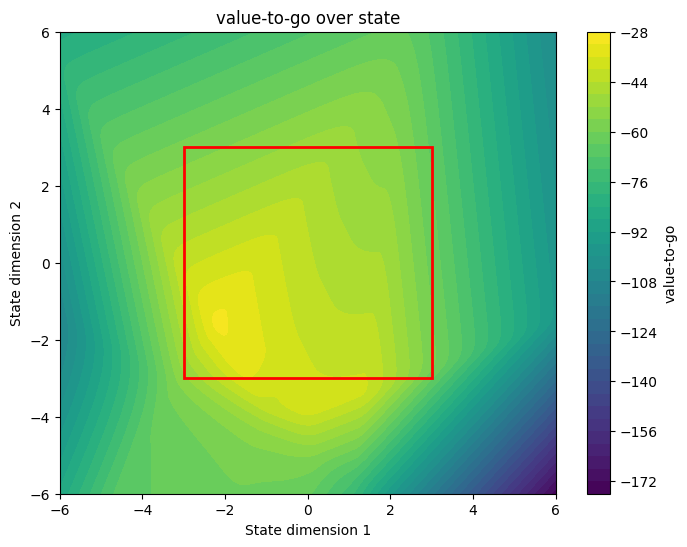

In [15]:
view_range = 6.0
samples_per_axis = 1_000
axis_samples = jnp.linspace(-view_range, view_range, samples_per_axis)
X, Y = jnp.meshgrid(axis_samples, axis_samples, indexing="xy")
states = jnp.stack((X.flatten(), Y.flatten()), axis=-1)

value_to_go.eval()
costs = nnx.vmap(lambda state: value_to_go(state, rngs=nnx.Rngs(0)))(
    states,
)
costs = costs.squeeze().reshape(samples_per_axis, samples_per_axis)

fig, ax = plt.subplots(figsize=(8, 6))
c = ax.contourf(
    states[:, 0].reshape(samples_per_axis, samples_per_axis),
    states[:, 1].reshape(samples_per_axis, samples_per_axis),
    costs,
    levels=45,
    cmap="viridis",
)
rect = plt.Rectangle((-3, -3), 6, 6, linewidth=2, edgecolor="red", facecolor="none")
ax.add_patch(rect)
fig.colorbar(c, ax=ax, label="value-to-go")
ax.set_xlabel("State dimension 1")
ax.set_ylabel("State dimension 2")
ax.set_title("value-to-go over state")
plt.show()

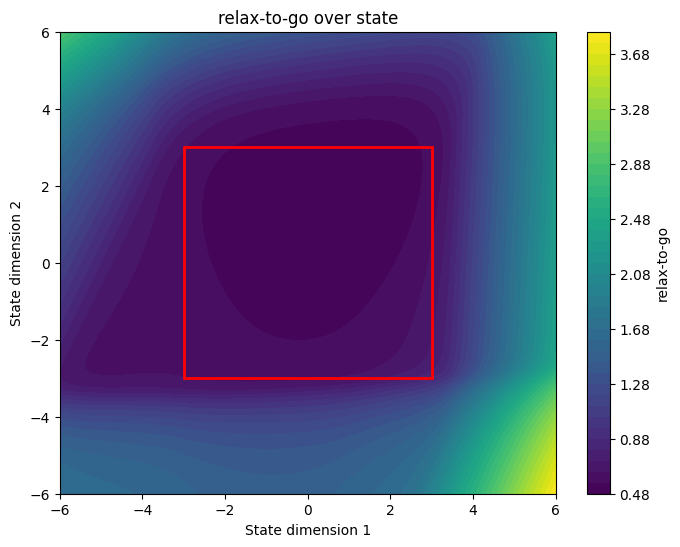

In [16]:
relax_to_go.eval()
costs = nnx.vmap(lambda state: relax_to_go(state, rngs=nnx.Rngs(0)))(
    states,
)
costs = costs.squeeze().reshape(samples_per_axis, samples_per_axis)

fig, ax = plt.subplots(figsize=(8, 6))
c = ax.contourf(
    states[:, 0].reshape(samples_per_axis, samples_per_axis),
    states[:, 1].reshape(samples_per_axis, samples_per_axis),
    costs,
    levels=45,
    cmap="viridis",
)
rect = plt.Rectangle((-3, -3), 6, 6, linewidth=2, edgecolor="red", facecolor="none")
ax.add_patch(rect)
fig.colorbar(c, ax=ax, label="relax-to-go")
ax.set_xlabel("State dimension 1")
ax.set_ylabel("State dimension 2")
ax.set_title("relax-to-go over state")
plt.show()